# BabyLM Strict-Small: sweep results and evaluation

This notebook has three parts:

1. **The sweep:** 10 runs, each with a different learning rate, gradient accumulation and LR schedule.
2. **The best run (sweep-04):** its validation curve in detail.
3. **BabyLM evaluation:** zero-shot scores for the sweep-04 final checkpoint, next to the GPT-2 baseline.

**Before running:** put this notebook in your `pico-train` folder, next to `sweep_val_ppl.csv` and the `babylm_results` folder (the copy of `results/` from the cluster). If your files are elsewhere, change the paths in the next cell.

In [4]:
import glob
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ---- paths: change these if your files live somewhere else ----
SWEEP_CSV = "sweep_val_ppl.csv"
RESULTS_DIR = "babylm_results"  # folder copied from the cluster's strict/results
BEST_RUN = "sweep-04"
MICRO_BATCH = 8  # MB used in the final sweep Jobs (effective batch = 8 x accumulation)
WORDS_PER_EPOCH = 9_499_705  # from data_stats.json (95% of 10M words; 5% held out)

sns.set_theme(style="whitegrid", context="notebook")
million = FuncFormatter(lambda x, _: f"{x/1e6:g}M")

## 1. Load the sweep results

In [5]:
df = pd.read_csv(SWEEP_CSV)
df = df.drop_duplicates(subset=["run", "step"], keep="last").sort_values(
    ["run", "step"]
)
df["effective_batch"] = MICRO_BATCH * df["grad_accum"]
print(f"{df['run'].nunique()} runs, {len(df)} validation checkpoints")
df.head()

10 runs, 190 validation checkpoints


,run,step,samples_seen,words_seen,val_loss,val_ppl,lr,grad_accum,schedule,effective_batch
0,sweep-00,202,3232,1001829,10.869432,52545.3796,0.000019,2,linear,16
1,sweep-00,403,6448,1998698,10.632816,41473.7640,0.000019,2,linear,16
2,sweep-00,605,9680,3000527,10.169178,26086.6250,0.000019,2,linear,16
3,sweep-00,807,12912,4002356,9.501018,13373.3282,0.000019,2,linear,16
4,sweep-00,1008,16128,4999225,8.753871,6335.1639,0.000019,2,linear,16


### Summary of the 10 runs

Sorted by **final** validation perplexity (lower is better). `best_ppl` is the lowest value seen at any checkpoint; for a run that keeps improving it matches the final one. The assignment objective is validation perplexity, so say in your write-up which of the two you used (here: final).

In [6]:
summary = (
    df.groupby("run")
    .agg(
        lr=("lr", "first"),
        grad_accum=("grad_accum", "first"),
        schedule=("schedule", "first"),
        effective_batch=("effective_batch", "first"),
        optimizer_steps=("step", "max"),
        checkpoints=("step", "count"),
        words_seen=("words_seen", "max"),
        final_ppl=("val_ppl", "last"),
        best_ppl=("val_ppl", "min"),
    )
    .sort_values("final_ppl")
)
summary["words_seen"] = (summary["words_seen"] / 1e6).round(1).astype(str) + "M"
summary.style.format(
    {
        "lr": "{:.2e}",
        "final_ppl": "{:,.2f}",
        "best_ppl": "{:,.2f}",
        "optimizer_steps": "{:,}",
    }
).background_gradient(subset=["final_ppl"], cmap="RdYlGn_r")

,lr,grad_accum,schedule,effective_batch,optimizer_steps,checkpoints,words_seen,final_ppl,best_ppl
run,,,,,,,,,
sweep-04,4.28e-05,1,linear,8,"38,308",19,95.0M,66.18,66.18
sweep-02,6.69e-05,5,cosine,40,"7,661",19,95.0M,87.46,87.46
sweep-00,1.88e-05,2,linear,16,"19,154",19,95.0M,123.90,123.90
sweep-09,1.97e-05,6,cosine,48,"6,384",19,95.0M,245.26,245.26
sweep-07,3.98e-06,3,cosine,24,"12,769",19,95.0M,"1,213.04","1,213.04"
sweep-03,1.22e-05,13,cosine,104,"2,946",19,95.0M,"1,735.70","1,735.70"
sweep-08,1.14e-06,1,linear,8,"38,308",19,95.0M,"2,697.08","2,697.08"
sweep-06,2.25e-06,11,linear,88,"3,482",19,95.0M,"23,737.26","23,737.26"
sweep-05,1.17e-06,8,cosine,64,"4,788",19,95.0M,"31,225.00","31,225.00"


### Validation perplexity over training, all runs

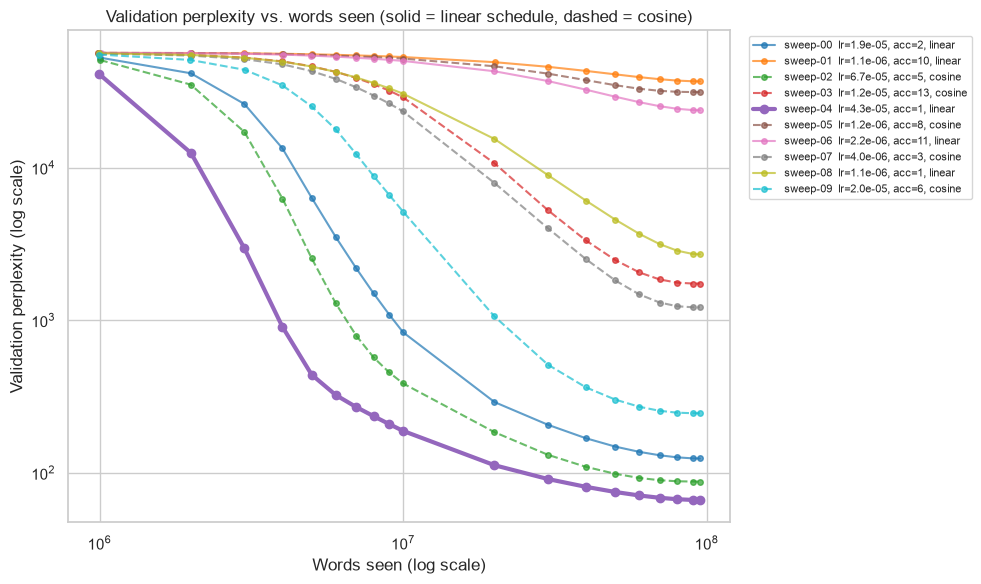

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
palette = sns.color_palette("tab10", df["run"].nunique())
for (run, g), color in zip(df.groupby("run"), palette):
    is_best = run == BEST_RUN
    ax.plot(
        g["words_seen"],
        g["val_ppl"],
        marker="o",
        ms=4 if not is_best else 6,
        lw=3 if is_best else 1.5,
        alpha=1 if is_best else 0.7,
        color=color,
        ls="-" if g["schedule"].iloc[0] == "linear" else "--",
        label=f"{run}  lr={g['lr'].iloc[0]:.1e}, acc={g['grad_accum'].iloc[0]}, {g['schedule'].iloc[0]}",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Words seen (log scale)")
ax.set_ylabel("Validation perplexity (log scale)")
ax.set_title(
    "Validation perplexity vs. words seen (solid = linear schedule, dashed = cosine)"
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Reading this plot: the x-axis is log-scaled because the BabyLM checkpoint schedule is dense early (every 1M words up to 10M, then every 10M). Runs with a tiny learning rate (around 1e-6) barely leave the starting perplexity (about the vocabulary size, ~50,000). The best run is the thick line.

### What drives final perplexity?

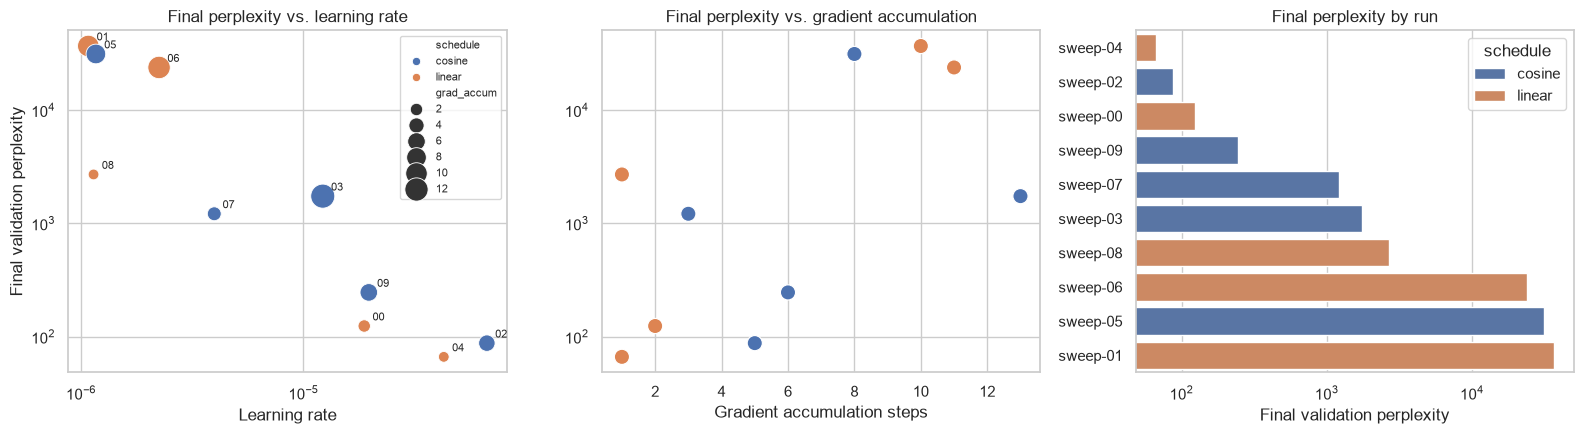

In [8]:
final = df.sort_values("step").groupby("run").tail(1).copy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(
    data=final,
    x="lr",
    y="final_ppl" if "final_ppl" in final else "val_ppl",
    hue="schedule",
    size="grad_accum",
    sizes=(60, 300),
    ax=axes[0],
)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Final perplexity vs. learning rate")
axes[0].legend(loc="upper right", fontsize=8, title_fontsize=8)
axes[0].set_xlabel("Learning rate")
axes[0].set_ylabel("Final validation perplexity")
for _, r in final.iterrows():
    axes[0].annotate(
        r["run"].replace("sweep-", ""),
        (r["lr"], r["val_ppl"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8,
    )

sns.scatterplot(
    data=final,
    x="grad_accum",
    y="val_ppl",
    hue="schedule",
    s=120,
    ax=axes[1],
    legend=False,
)
axes[1].set_yscale("log")
axes[1].set_title("Final perplexity vs. gradient accumulation")
axes[1].set_xlabel("Gradient accumulation steps")
axes[1].set_ylabel("")

order = final.sort_values("val_ppl")["run"]
sns.barplot(
    data=final,
    y="run",
    x="val_ppl",
    order=order,
    hue="schedule",
    dodge=False,
    ax=axes[2],
)
axes[2].set_xscale("log")
axes[2].set_title("Final perplexity by run")
axes[2].set_xlabel("Final validation perplexity")
axes[2].set_ylabel("")
plt.tight_layout()
plt.show()

**How to read it:** accumulation sets the effective batch size, and with a fixed 10 epochs a larger batch means fewer optimizer updates. Compare the left and middle panels. With only 10 random points, treat any trend as suggestive, not conclusive.

## 2. The best run in detail

In [9]:
best = df[df["run"] == BEST_RUN].copy()
cfg = best.iloc[0]
print(
    f"{BEST_RUN}: lr={cfg['lr']:.3e}, gradient accumulation={cfg['grad_accum']}, "
    f"schedule={cfg['schedule']}, effective batch={cfg['effective_batch']}"
)
print(
    f"Optimizer steps: {best['step'].max():,}   Words seen: {best['words_seen'].max()/1e6:.1f}M"
)
print(
    f"Final validation perplexity: {best['val_ppl'].iloc[-1]:.2f}   (loss {best['val_loss'].iloc[-1]:.3f})"
)

sweep-04: lr=4.283e-05, gradient accumulation=1, schedule=linear, effective batch=8
Optimizer steps: 38,308   Words seen: 95.0M
Final validation perplexity: 66.18   (loss 4.192)


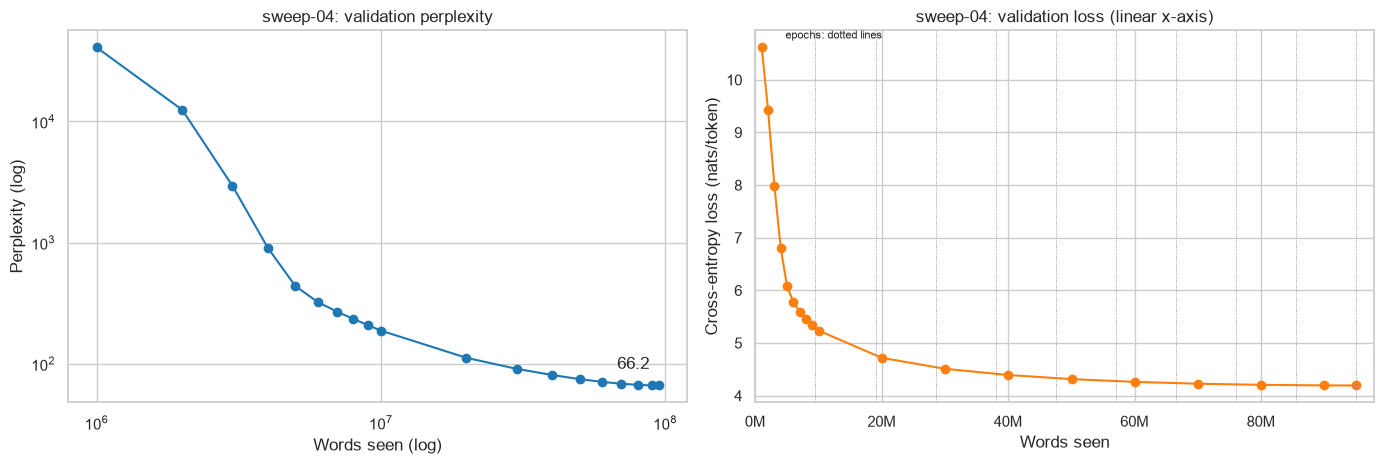

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(best["words_seen"], best["val_ppl"], marker="o", color="tab:blue")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title(f"{BEST_RUN}: validation perplexity")
axes[0].set_xlabel("Words seen (log)")
axes[0].set_ylabel("Perplexity (log)")
axes[0].annotate(
    f"{best['val_ppl'].iloc[-1]:.1f}",
    (best["words_seen"].iloc[-1], best["val_ppl"].iloc[-1]),
    textcoords="offset points",
    xytext=(-30, 12),
)

axes[1].plot(best["words_seen"], best["val_loss"], marker="o", color="tab:orange")
axes[1].set_xlim(0, best["words_seen"].max() * 1.03)
axes[1].xaxis.set_major_formatter(million)
axes[1].set_title(f"{BEST_RUN}: validation loss (linear x-axis)")
axes[1].set_xlabel("Words seen")
axes[1].set_ylabel("Cross-entropy loss (nats/token)")
for e in range(1, 11):  # epoch boundaries
    axes[1].axvline(e * WORDS_PER_EPOCH, color="gray", lw=0.6, ls=":")
axes[1].text(
    WORDS_PER_EPOCH * 0.5,
    axes[1].get_ylim()[1],
    "epochs: dotted lines",
    fontsize=8,
    va="top",
)
plt.tight_layout()
plt.show()

### Every validation checkpoint for the best run

In [11]:
tbl = best[["step", "words_seen", "val_loss", "val_ppl"]].copy()
tbl["epoch"] = (tbl["words_seen"] / WORDS_PER_EPOCH).round(2)
tbl["words_seen"] = (tbl["words_seen"] / 1e6).round(2)
tbl = tbl.rename(columns={"words_seen": "words_seen (M)"})
tbl.style.format({"val_loss": "{:.3f}", "val_ppl": "{:,.2f}"}).hide(axis="index")

step,words_seen (M),val_loss,val_ppl,epoch
403,1.000000,10.617,"40,832.80",0.110000
807,2.000000,9.430,"12,453.17",0.210000
1210,3.000000,7.991,"2,954.63",0.320000
1613,4.000000,6.810,907.03,0.420000
2016,5.000000,6.083,438.45,0.530000
2420,6.000000,5.777,322.75,0.630000
2823,7.000000,5.597,269.53,0.740000
3226,8.000000,5.457,234.49,0.840000
3629,9.000000,5.338,208.19,0.950000
4033,10.000000,5.235,187.82,1.050000


### Optional: training loss for the best run

Training loss isn't in the CSV; it lives in Weights & Biases. To add it: open the `babylm-sweep` project, click the table icon on the `train/loss` chart, export CSV, and save it as `train_loss_sweep04.csv` next to this notebook. This cell does nothing if the file isn't there.

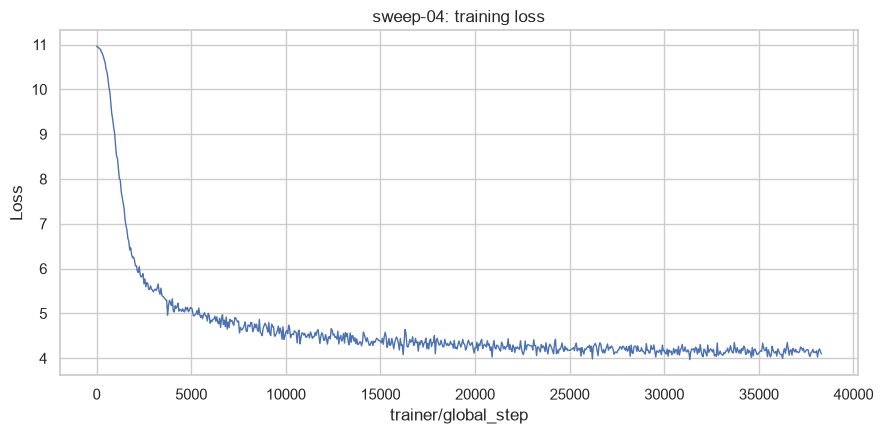

In [16]:
path = "train_loss_sweep04.csv"
if os.path.exists(path):
    tl = pd.read_csv(path)
    x = next((c for c in tl.columns if "step" in c.lower()), tl.columns[0])
    y = next(
        (
            c
            for c in tl.columns
            if "loss" in c.lower() and "MIN" not in c and "MAX" not in c
        ),
        tl.columns[1],
    )
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(tl[x], tl[y], lw=1)
    ax.set_title(f"{BEST_RUN}: training loss")
    ax.set_xlabel(x)
    ax.set_ylabel("Loss")
    plt.tight_layout()
    plt.show()
else:
    print(f"{path} not found - skipping (see the note above).")

## 3. BabyLM evaluation (zero-shot)

These are the scores for the sweep-04 final checkpoint (`step_38308`). Each report file is parsed for its overall accuracy. If a file can't be parsed or isn't present, the cell falls back to the numbers printed by `print_results_table.py` and tells you so.

Baselines are the GPT-2 Strict-Small numbers from the babylm-eval README. EWoK was run on the **fast subset only** (the repo ships EWoK full data separately), so it isn't comparable to the baseline.

In [13]:
# Values copied from the printed results table (used only as a fallback)
FALLBACK = {
    "blimp_filtered": 53.90,
    "supplement_filtered": 54.25,
    "comps": 50.47,
    "entity_tracking": 16.99,
    "ewok_fast": 47.82,
}
LABELS = {
    "blimp_filtered": "BLiMP",
    "supplement_filtered": "BLiMP Supplement",
    "comps": "COMPS",
    "entity_tracking": "Entity Tracking",
    "ewok_fast": "EWoK (fast subset)",
}
BASELINE = {
    "blimp_filtered": 65.08,
    "supplement_filtered": 57.25,
    "comps": 51.81,
    "entity_tracking": 21.07,
    "ewok_fast": np.nan,
}
CHANCE = {
    "blimp_filtered": 50,
    "supplement_filtered": 50,
    "comps": 50,
    "entity_tracking": np.nan,
    "ewok_fast": 50,
}


def parse_report(path):
    txt = open(path, encoding="utf-8", errors="ignore").read()
    m = re.search(r"AVERAGE ACCURACY\s*\n\s*([\d.]+)", txt, flags=re.I)
    return float(m.group(1)) if m else None


scores, source = {}, {}
for p in glob.glob(
    os.path.join(RESULTS_DIR, "**", "best_temperature_report.txt"), recursive=True
):
    task = os.path.basename(os.path.dirname(p))
    val = parse_report(p)
    if val is not None:
        scores[task], source[task] = val, "report file"
for task, val in FALLBACK.items():
    if task not in scores:
        scores[task], source[task] = val, "printed table (fallback)"

ev = pd.DataFrame(
    {
        "task": [LABELS.get(t, t) for t in scores],
        "your_model": list(scores.values()),
        "gpt2_baseline": [BASELINE.get(t, np.nan) for t in scores],
        "chance": [CHANCE.get(t, np.nan) for t in scores],
        "source": list(source.values()),
    }
)
ORDER = ["BLiMP", "BLiMP Supplement", "EWoK (fast subset)", "COMPS", "Entity Tracking"]
ev["task"] = pd.Categorical(
    ev["task"],
    categories=ORDER + [t for t in ev["task"] if t not in ORDER],
    ordered=True,
)
ev = ev.sort_values("task").reset_index(drop=True)
ev["vs_baseline"] = ev["your_model"] - ev["gpt2_baseline"]
ev.style.format(
    {
        "your_model": "{:.2f}",
        "gpt2_baseline": "{:.2f}",
        "chance": "{:.0f}",
        "vs_baseline": "{:+.2f}",
    },
    na_rep="-",
).hide(axis="index")

task,your_model,gpt2_baseline,chance,source,vs_baseline
BLiMP,53.90,65.08,50,report file,-11.18
BLiMP Supplement,54.25,57.25,50,report file,-3.00
EWoK (fast subset),47.82,-,50,report file,-
COMPS,50.47,51.81,50,report file,-1.34
Entity Tracking,16.99,21.07,-,report file,-4.08


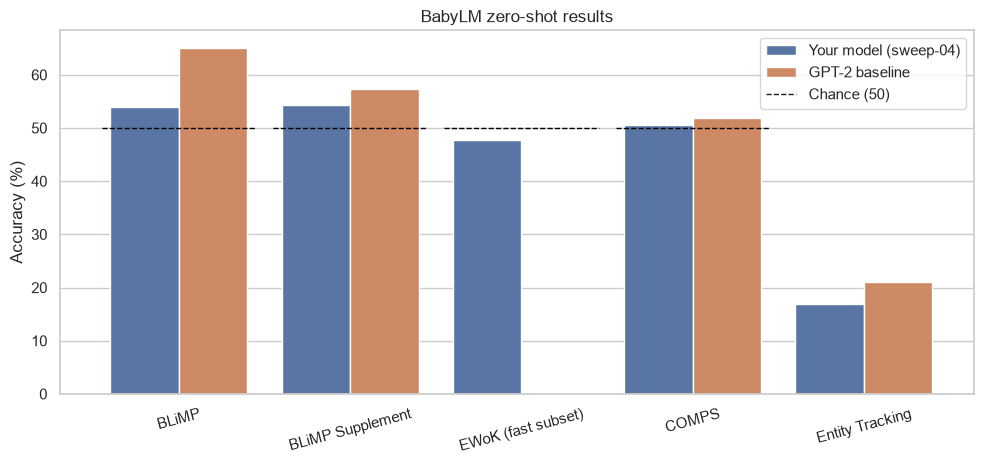

In [14]:
plot_df = (
    ev.assign(task=ev["task"].astype(str))
    .melt(
        id_vars="task",
        value_vars=["your_model", "gpt2_baseline"],
        var_name="who",
        value_name="accuracy",
    )
    .dropna()
)
plot_df["who"] = plot_df["who"].map(
    {"your_model": "Your model (sweep-04)", "gpt2_baseline": "GPT-2 baseline"}
)
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(
    data=plot_df,
    x="task",
    y="accuracy",
    hue="who",
    order=list(ev["task"].astype(str)),
    ax=ax,
)
for i, row in ev.reset_index(drop=True).iterrows():
    if not np.isnan(row["chance"]):
        ax.hlines(
            row["chance"], i - 0.45, i + 0.45, colors="black", linestyles="dashed", lw=1
        )
ax.plot([], [], "k--", lw=1, label="Chance (50)")
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("")
ax.set_title("BabyLM zero-shot results")
plt.xticks(rotation=15)
ax.legend()
plt.tight_layout()
plt.show()

### Breakdown within each task

Some reports list accuracy by subcategory (for example EWoK context-contrast and target-contrast items). This prints them if they're present.

In [15]:
rows = []
for p in glob.glob(
    os.path.join(RESULTS_DIR, "**", "best_temperature_report.txt"), recursive=True
):
    task = os.path.basename(os.path.dirname(p))
    section = None
    for line in open(p, encoding="utf-8", errors="ignore"):
        line = line.strip()
        if line.startswith("###"):
            section = line.strip("# ").title()
            continue
        m = re.match(r"^(.+?):\s*([\d.]+)$", line)
        if m and section and "Average" not in section:
            rows.append(
                {
                    "task": LABELS.get(task, task),
                    "section": section,
                    "category": m.group(1),
                    "accuracy": float(m.group(2)),
                }
            )
sub = pd.DataFrame(rows)
if sub.empty:
    print("No subcategory breakdowns found in the report files.")
else:
    sub.sort_values(["task", "section", "accuracy"]).style.format(
        {"accuracy": "{:.2f}"}
    ).hide(axis="index")

## Summary and caveats

Fill in the numbers from the cells above.

- **Sweep:** 10 random-search runs (log-uniform learning rate in [1e-6, 1e-4], log-uniform gradient accumulation in [1, 16], linear or cosine schedule), each trained for 10 epochs. The best run by final validation perplexity was **sweep-04** (see the table in section 1).
- **Model:** 4-layer decoder, `d_model` 96, OLMo tokenizer (50k vocabulary), fp16 mixed precision, micro-batch 8 (reduced after out-of-memory errors on small GPUs; 48 fit on a 32 GB V100).
- **Evaluation:** scores are close to chance on all zero-shot tasks and below the GPT-2 Strict-Small baseline. Plausible reasons: a very small model, a large generic tokenizer, and a modest training recipe. These are hypotheses, not tested conclusions.
- **Limits:** random search with 10 points and one seed, so small differences between runs may be noise. Validation uses a 5% held-out split of the training text. EWoK used the fast subset only.